# Compare CNN Backbones

## Objective 4

Compare ResNet, EfficientNet and MobileNet based on:

- Clean TrashNet Accuracy
- Cross-Domain (RealWaste) Accuracy
- Inference Speed (ms/image)

Outputs:

- backbone_comparison.csv
- backbone_comparison_chart.png

In [1]:
import json
import os
import time

import torch
import pandas as pd
import matplotlib.pyplot as plt

import config
from models import build_model

In [2]:
@torch.no_grad()
def benchmark_inference(backbone_name, num_warmup=10, num_runs=50):
    """
    Average per-image inference time (milliseconds).
    """

    device = config.DEVICE

    model, _ = build_model(
        backbone_name,
        len(config.TRASHNET_CLASSES),
        pretrained=False
    )

    model = model.to(device)
    model.eval()

    dummy = torch.randn(
        1,
        3,
        config.IMG_SIZE,
        config.IMG_SIZE,
        device=device
    )

    # Warm-up
    for _ in range(num_warmup):
        model(dummy)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()

    for _ in range(num_runs):
        model(dummy)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - start

    ms_per_image = (elapsed / num_runs) * 1000

    return ms_per_image

In [3]:
def build_comparison_table():

    rows = []

    for backbone in config.BACKBONES:

        row = {"backbone": backbone}

        # TrashNet Results
        trashnet_path = os.path.join(
            config.RESULTS_DIR,
            f"{backbone}_trashnet_results.json"
        )

        if os.path.exists(trashnet_path):

            with open(trashnet_path) as f:
                d = json.load(f)

            row["trashnet_clean_test_acc"] = d.get(
                "trashnet_test_accuracy"
            )

            row["trashnet_clean_test_macro_f1"] = d.get(
                "trashnet_test_macro_f1"
            )

        # Cross-Domain Results
        cross_path = os.path.join(
            config.RESULTS_DIR,
            f"{backbone}_cross_domain_results.json"
        )

        if os.path.exists(cross_path):

            with open(cross_path) as f:
                d = json.load(f)

            row["realwaste_zero_shot_acc"] = d.get(
                "realwaste_zero_shot_accuracy"
            )

            row["realwaste_zero_shot_macro_f1"] = d.get(
                "realwaste_zero_shot_macro_f1"
            )

            row["clean_to_real_gap"] = d.get(
                "clean_to_real_gap"
            )

        row["inference_ms_per_image"] = benchmark_inference(backbone)

        rows.append(row)

    df = pd.DataFrame(rows)

    csv_path = os.path.join(
        config.RESULTS_DIR,
        "backbone_comparison.csv"
    )

    df.to_csv(csv_path, index=False)

    print(df)

    print(f"Saved comparison table -> {csv_path}")

    return df

In [4]:
def plot_results(df):

    if "trashnet_clean_test_acc" not in df.columns:
        return

    fig, ax1 = plt.subplots(figsize=(7,5))

    x = range(len(df))

    ax1.bar(
        x,
        df["trashnet_clean_test_acc"],
        width=0.35,
        label="TrashNet Accuracy"
    )

    if "realwaste_zero_shot_acc" in df.columns:

        ax1.bar(
            [i + 0.35 for i in x],
            df["realwaste_zero_shot_acc"],
            width=0.35,
            label="RealWaste Accuracy"
        )

    ax1.set_xticks([i + 0.175 for i in x])
    ax1.set_xticklabels(df["backbone"])

    ax1.set_ylim(0,1)

    ax1.set_ylabel("Accuracy")

    ax1.legend(loc="upper left")

    ax2 = ax1.twinx()

    ax2.plot(
        x,
        df["inference_ms_per_image"],
        marker="o",
        label="Inference (ms/image)"
    )

    ax2.set_ylabel("Inference Time")

    ax2.legend(loc="upper right")

    plt.title("Backbone Comparison")

    plt.tight_layout()

    chart_path = os.path.join(
        config.RESULTS_DIR,
        "backbone_comparison_chart.png"
    )

    plt.savefig(chart_path, dpi=150)

    plt.show()

    print(f"Saved chart -> {chart_path}")

             backbone  trashnet_clean_test_acc  trashnet_clean_test_macro_f1  \
0            resnet50                 0.942105                      0.934579   
1     efficientnet_b0                 0.947368                      0.939143   
2  mobilenet_v3_large                 0.963158                      0.958331   

   realwaste_zero_shot_acc  realwaste_zero_shot_macro_f1  clean_to_real_gap  \
0                  0.37722                      0.351224           0.564885   
1                      NaN                           NaN                NaN   
2                      NaN                           NaN                NaN   

   inference_ms_per_image  
0               96.306882  
1               29.861503  
2               20.123248  
Saved comparison table -> e:\wasteClassificationProject_FIXED\wasteClassificationProject\outputs\backbone_comparison.csv


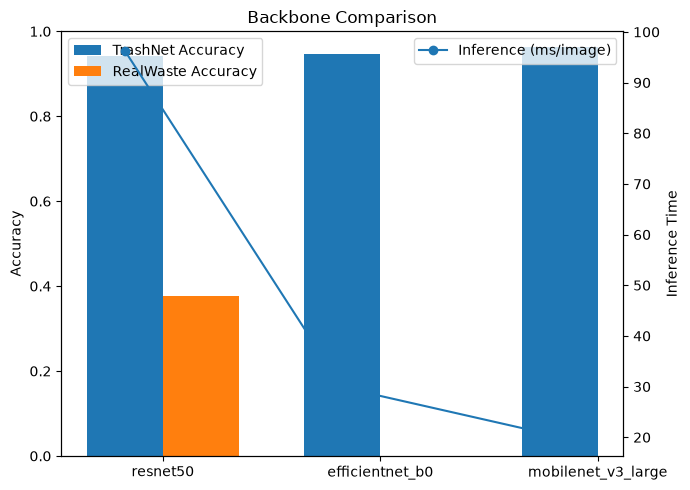

Saved chart -> e:\wasteClassificationProject_FIXED\wasteClassificationProject\outputs\backbone_comparison_chart.png


In [5]:
df = build_comparison_table()

plot_results(df)

In [6]:
df

,backbone,trashnet_clean_test_acc,trashnet_clean_test_macro_f1,realwaste_zero_shot_acc,realwaste_zero_shot_macro_f1,clean_to_real_gap,inference_ms_per_image
0,resnet50,0.942105,0.934579,0.37722,0.351224,0.564885,96.306882
1,efficientnet_b0,0.947368,0.939143,NaN,NaN,NaN,29.861503
2,mobilenet_v3_large,0.963158,0.958331,NaN,NaN,NaN,20.123248
